In [1]:
from pathlib import Path

In [2]:
data = Path("/scratch/project_2008523/era5")

In [3]:
import numpy as np
import pandas as pd
import xarray as xr

In [7]:
ds_mean = xr.open_dataset(data / "3e36e22482d4e90c2f7d18740c1ba838" / "data_0.nc", chunks={})
ds_mean

<xarray.Dataset> Size: 3GB
Dimensions:     (valid_time: 248, latitude: 361, longitude: 720)
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 2kB 2023-12-01 ... 2023-12-31T21:...
  * latitude    (latitude) float64 3kB 90.0 89.5 89.0 88.5 ... -89.0 -89.5 -90.0
  * longitude   (longitude) float64 6kB 0.0 0.5 1.0 1.5 ... 358.5 359.0 359.5
    expver      (valid_time) <U4 4kB dask.array<chunksize=(248,), meta=np.ndarray>
Data variables:
    istl1       (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    istl2       (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    istl3       (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    istl4       (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    swvl1       (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    swvl2       (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    swvl3       (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    swvl4       (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    stl1        (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    stl2        (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    stl3        (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    stl4        (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts

In [8]:
ds_spread = xr.open_dataset(data / "3e36e22482d4e90c2f7d18740c1ba838" / "data_1.nc", chunks={})
ds_spread

<xarray.Dataset> Size: 3GB
Dimensions:     (valid_time: 248, latitude: 361, longitude: 720)
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 2kB 2023-12-01 ... 2023-12-31T21:...
  * latitude    (latitude) float64 3kB 90.0 89.5 89.0 88.5 ... -89.0 -89.5 -90.0
  * longitude   (longitude) float64 6kB 0.0 0.5 1.0 1.5 ... 358.5 359.0 359.5
    expver      (valid_time) <U4 4kB dask.array<chunksize=(248,), meta=np.ndarray>
Data variables:
    istl1       (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    istl2       (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    istl3       (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    istl4       (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    swvl1       (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    swvl2       (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    swvl3       (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    swvl4       (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    stl1        (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    stl2        (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    stl3        (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
    stl4        (valid_time, latitude, longitude) float32 258MB dask.array<chunksize=(83, 121, 240), meta=np.ndarray>
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts

In [9]:
import textwrap

from matplotlib import pyplot as plt

In [10]:
def plot_ensemble_mean_spread(key, ax, lax, sample=slice(None)):
    mean = ds_mean[key]
    spread = ds_spread[key]

    abs_cns, abs_prg = np.nanquantile(spread.where(spread > 0.0), [0.0, 0.01])

    abs_mean = np.abs(mean)
    rel = spread.where(abs_mean > 0.0) / abs_mean.where(abs_mean > 0.0)
    rel_cns, rel_prg = np.nanquantile(rel.where(rel > 0.0), [0.0, 0.01])

    months = sorted(set(zip(
        pd.to_datetime(mean.valid_time).year,
        pd.to_datetime(mean.valid_time).month,
    )))
    colours = ["tab:orange", "tab:blue"]
    
    ax.set_title(f"{'\n'.join(textwrap.wrap(mean.long_name, width=22, break_long_words=False))}")
    ax.set_xlabel(f"mean [{mean.units}]")
    ax.set_ylabel(f"spread [{spread.units}]")

    if key in ():
        ax.set_xscale("log")
        ax.set_yscale("log")

    handles = []

    for (year, month), colour in zip(months, colours):
        handles.append(ax.scatter(
            mean.sel(valid_time=f"{year}-{month:02}").values.flatten()[sample],
            spread.sel(valid_time=f"{year}-{month:02}").values.flatten()[sample],
            s=1, label=f"{year}/{month:02}", edgecolor="none", marker=".", c=colour,
        ))

    legends = []

    legends.append(ax.axhline(abs_cns, c="red", ls="--", label=f"$abs_{{cns}} = {abs_cns:.03}$"))
    legends.append(ax.axhline(abs_prg, c="red", ls=":", label=f"$abs_{{prg}} = {abs_prg:.03}$"))

    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    rlim = sorted([xlim[0], 0.0, xlim[1]])

    legends.extend(ax.plot(rlim, np.array(rlim) * rel_cns * np.sign(rlim), c="blue", ls="--", label=f"$rel_{{cns}} = {rel_cns:.03}$"))
    legends.extend(ax.plot(rlim, np.array(rlim) * rel_prg * np.sign(rlim), c="blue", ls=":", label=f"$rel_{{prg}} = {rel_prg:.03}$"))

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

    lax.axis("off")
    lax.legend(handles=legends, loc="center")

    return handles

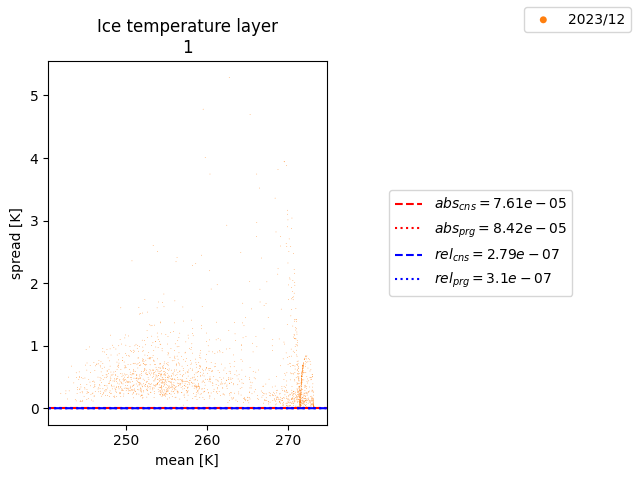

In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2)

handles = plot_ensemble_mean_spread("istl1", ax1, ax2, sample=slice(0, None, 5000))

fig.legend(handles=handles, loc="upper right", markerscale=10)

fig.tight_layout()
plt.show()

In [16]:
import fcbench

In [13]:
def plot_bitinformation(key, ax):
    mean = ds_mean[key]

    months = sorted(set(zip(
        pd.to_datetime(mean.valid_time).year,
        pd.to_datetime(mean.valid_time).month,
    )))
    colours = ["tab:orange", "tab:blue"]
    
    ax.set_title(f"{'\n'.join(textwrap.wrap(mean.long_name, width=22, break_long_words=False))}")
    
    ax.set_xlabel("bit index")
    ax.set_xticks([0, 8.5, 31])
    ax.set_ylabel("information [bits]")

    handles = []

    for (year, month), colour in zip(months, colours):
        bit_information = fcbench.metrics.BitInformation.bit_information(
            mean.sel(valid_time=f"{year}-{month:02}"),
            set_zero_insignificant_confidence=0.99,
        )

        p99 = np.searchsorted(np.cumsum(bit_information) / np.sum(bit_information), 0.99)
        ax.axvline(p99, c=colour, ls=":")
        
        handles.extend(ax.plot(
            np.arange(32), bit_information, label=f"{year}/{month:02}", c=colour,
        ))

    ax.axvline(8.5, c="black", ls="--")

    return handles

In [36]:
bit_information = fcbench.metrics.BitInformation.bit_information(
    ds_mean["istl1"],
    set_zero_insignificant_confidence=0.99,
)
bit_information

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.29997199, 0.29997199,
       0.29997199, 0.29993073, 0.31864851, 0.313079  , 0.29394216,
       0.28065118, 0.22188096, 0.19852621, 0.18021221, 0.11942831,
       0.12160292, 0.11040861, 0.10756689, 0.08597056, 0.09756833,
       0.09269681, 0.61228476, 0.75672362, 0.98139918, 0.98893669,
       0.96879266, 0.86744163])

In [37]:
bit_information_mantissa = bit_information[9:]
bit_information_mantissa

array([0.29997199, 0.29997199, 0.29993073, 0.31864851, 0.313079  ,
       0.29394216, 0.28065118, 0.22188096, 0.19852621, 0.18021221,
       0.11942831, 0.12160292, 0.11040861, 0.10756689, 0.08597056,
       0.09756833, 0.09269681, 0.61228476, 0.75672362, 0.98139918,
       0.98893669, 0.96879266, 0.86744163])

In [38]:
increasing = np.round(bit_information_mantissa[1:], 2) >= np.round(bit_information_mantissa[:-1], 2)
increasing

array([ True,  True,  True, False, False, False, False, False, False,
       False,  True, False,  True, False,  True, False,  True,  True,
        True,  True, False, False])

In [44]:
imax = np.where(~increasing)[0][0]
imax

3

In [45]:
bit_information_skyfall = bit_information[9+imax:]
bit_information_skyfall

array([0.31864851, 0.313079  , 0.29394216, 0.28065118, 0.22188096,
       0.19852621, 0.18021221, 0.11942831, 0.12160292, 0.11040861,
       0.10756689, 0.08597056, 0.09756833, 0.09269681, 0.61228476,
       0.75672362, 0.98139918, 0.98893669, 0.96879266, 0.86744163])

In [46]:
decreasing = np.round(bit_information_skyfall[1:], 2) <= np.round(bit_information_skyfall[:-1], 2)
decreasing

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True, False,  True, False, False, False, False,  True,
        True])

In [47]:
imin = np.where(~decreasing)[0][0]
imin

11

In [49]:
bit_information_corrected = np.copy(bit_information)
bit_information_corrected[9+imax+imin+1:] = 0.0
bit_information_corrected

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.29997199, 0.29997199,
       0.29997199, 0.29993073, 0.31864851, 0.313079  , 0.29394216,
       0.28065118, 0.22188096, 0.19852621, 0.18021221, 0.11942831,
       0.12160292, 0.11040861, 0.10756689, 0.08597056, 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        ])

In [75]:
keepbits_mantissa = imax + imin + 1
keepbits_mantissa

15

In [77]:
relative_error = np.exp2(-keepbits_mantissa)
relative_error

3.0517578125e-05

In [80]:
absolute_error = np.nanmin(np.abs(ds_mean["istl1"]).where(ds_mean["istl1"] != 0.0)) * relative_error
absolute_error

0.007260080426931381

In [81]:
ds_mean["istl1"]

<xarray.DataArray 'istl1' (valid_time: 248, latitude: 361, longitude: 720)> Size: 258MB
dask.array<open_dataset-istl1, shape=(248, 361, 720), dtype=float32, chunksize=(83, 121, 240), chunktype=numpy.ndarray>
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 2kB 2023-12-01 ... 2023-12-31T21:...
  * latitude    (latitude) float64 3kB 90.0 89.5 89.0 88.5 ... -89.0 -89.5 -90.0
  * longitude   (longitude) float64 6kB 0.0 0.5 1.0 1.5 ... 358.5 359.0 359.5
    expver      (valid_time) <U4 4kB dask.array<chunksize=(248,), meta=np.ndarray>
Attributes: (12/32)
    GRIB_paramId:                             35
    GRIB_dataType:                            em
    GRIB_numberOfPoints:                      259920
    GRIB_typeOfLevel:                         depthBelowLandLayer
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         10
    GRIB_units:                               K
    long_name:                                Ice temperature layer 1
    units:                                    K
    standard_name:                            unknown
    GRIB_depthBelowLandLayer:                 0.0

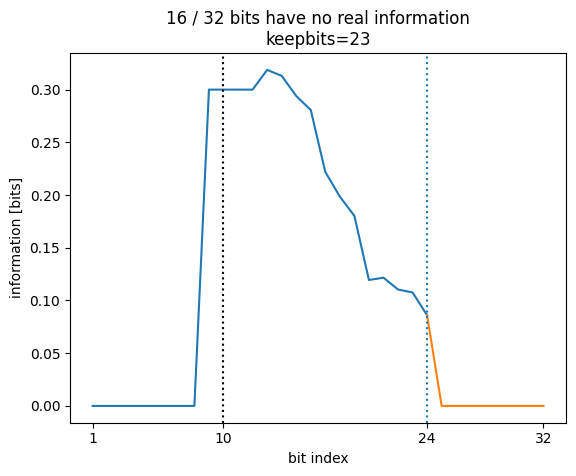

In [73]:
fig, ax = plt.subplots()

p99 = np.searchsorted(np.cumsum(bit_information_corrected) / np.sum(bit_information_corrected), 0.99)

ax.set_xlabel("bit index")
ax.set_xticks([1, 10, p99+1, 32])
ax.set_ylabel("information [bits]")

ax.set_title(
    f"{len(np.nonzero(bit_information_corrected)[0])} / 32 bits have no real information\n"
    f"keepbits={p99}"
)

ax.plot(np.arange(32)[:9+imax+imin+1] + 1, bit_information_corrected[:9+imax+imin+1])
ax.plot(np.arange(32)[9+imax+imin:] + 1, bit_information_corrected[9+imax+imin:])

ax.axvline(p99+1, ls=":")
ax.axvline(10, c="black", ls=":")

plt.show()

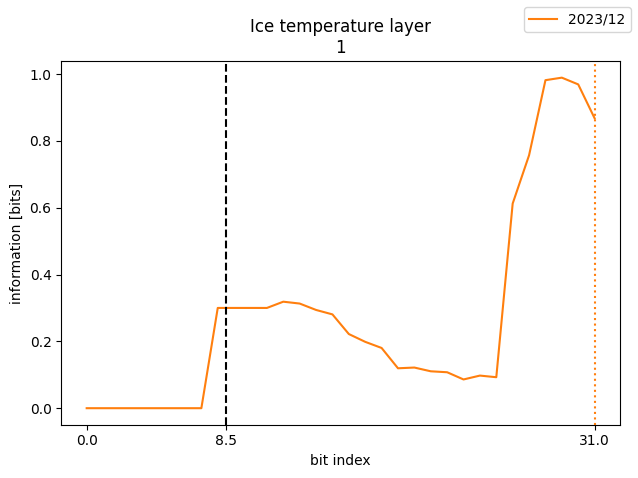

In [17]:
fig, ax = plt.subplots()

handles = plot_bitinformation("istl1", ax)

fig.legend(handles=handles, loc="upper right")

fig.tight_layout()
plt.show()

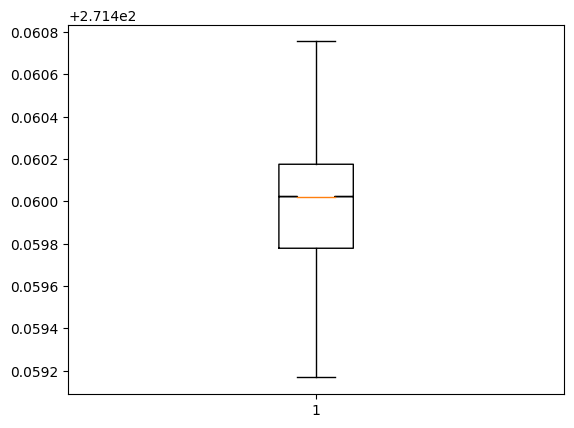

In [22]:
plt.boxplot(ds_mean["istl1"].values.flatten(), notch=True, showfliers=False)
plt.show()